In [156]:
## Plot the curve 
import matplotlib.pyplot as plt
import numpy as np
# SETUP 
import seaborn as sns 
plt.style.use('seaborn-v0_8-paper')

import os
os.environ["PATH"] += os.pathsep + os.path.expanduser("/home/runai-home/texlive/bin/x86_64-linux")

#plt.rc('font', family='Avenir', serif='Computer Modern')
text_size = 22
plt.rc('text', usetex=True)
plt.rc('xtick', labelsize=text_size)
plt.rc('ytick', labelsize=text_size)
plt.rc('axes', labelsize=text_size)
plt.rc('axes', titlesize=text_size)
plt.rc('legend',fontsize=18) # using a size in points
plt.rcParams['axes.linewidth'] = 1.15
plt.rcParams["figure.figsize"] = (6.,4.1631189606246317)
#plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"

rc = {"axes.spines.left" : True,
      "axes.spines.right" : True,
      "axes.spines.bottom" : True,
      "axes.spines.top" : True,
      "xtick.bottom" : True,
      "xtick.labelbottom" : True,
      "ytick.labelleft" : True,
      "ytick.left" : True
     }

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    #"font.sans-serif": ["Helvetica"]}
    "pgf.texsystem": "pdflatex",
    "pgf.preamble": r"\usepackage{bm}",
    "font.family": "serif",
    # Use LaTeX default serif font.
    "font.serif": ["Times"],
    # Use specific cursive fonts.
    "font.cursive": ["Comic Neue", "Comic Sans MS"],

})

plt.rcParams.update(rc)

In [157]:
# import matplotlib.pyplot as plt
# print(plt.style.available)

# Generalizability Test

['darkorange', 'forestgreen', 'dodgerblue', 'darkorchid']
[3.0, 2.933333333333333, 3.6, 3.8666666666666667, 2.8666666666666667, 3.6666666666666665, 3.933333333333333, 3.466666666666667]
[3.0, 3.1333333333333333, 4.2, 5.8, 4.866666666666666, 4.8, 4.466666666666667, 4.133333333333334, 4.6]
[3.0, 3.2666666666666666, 3.466666666666667, 3.8666666666666667, 5.0, 4.866666666666666, 4.2]
[3.0, 3.3333333333333335, 4.2, 5.133333333333334, 4.0, 4.333333333333333, 3.6666666666666665, 5.066666666666666, 5.866666666666666]


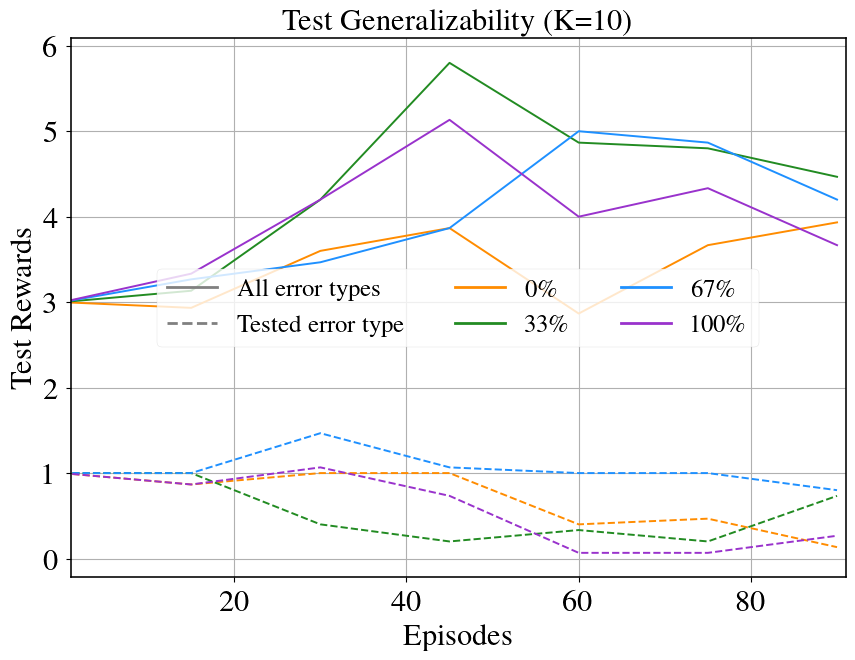

In [199]:
import pickle
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# with open('../vu2/RL4Auditing/tabular/generalization/30steps_0.pkl', 'rb') as file:
#     data = pickle.load(file)
# # Extract every 1000th element
# selected_elements = data["test_reward"]
# selected_elements_expl = data["test_reward_expl"]


# with open('../vu2/RL4Auditing/tabular/generalization/30steps_0.33.pkl', 'rb') as file:
#     data = pickle.load(file)
# # Extract every 1000th element
# selected_elements2 = data["test_reward"]
# selected_elements_expl2 = data["test_reward_expl"]

# with open('../vu2/RL4Auditing/tabular/generalization/30steps_0.67.pkl', 'rb') as file:
#     data = pickle.load(file)
# # Extract every 1000th element
# selected_elements3 = data["test_reward"]
# selected_elements_expl3 = data["test_reward_expl"]


# with open('../vu2/RL4Auditing/tabular/generalization/30steps_all.pkl', 'rb') as file:
#     data = pickle.load(file)
# # Extract every 1000th element
# selected_elements4 = data["test_reward"]
# selected_elements_expl4 = data["test_reward_expl"]

def average_chunks(lst, N):
    # Ensure that N is valid
    if N <= 0:
        raise ValueError("N must be greater than 0")
    
    # Create a new list to store the averages
    averages = []
    
    # Iterate over the list in chunks of size N
    for i in range(0, len(lst), N):
        chunk = lst[i:i + N]
        
        # Only average the chunk if it has exactly N elements
        if len(chunk) == N:
            avg = sum(chunk) / N
            averages.append(avg)
    
    return averages

def generate_colormap_colors(n, cmap='magma'):
    colormap = plt.get_cmap(cmap)
    return [colormap(i / n) for i in range(n)]

element = []
element_expl = []

lengths = []
N = 15
s = 10
file_base = '../vu2/RL4Auditing/tabular/generalization/'
list_result = ['%dsteps_0.pkl'%s, '%dsteps_0.33.pkl'%s, '%dsteps_0.67.pkl'%s, '%dsteps_1.pkl'%s] #

for l in list_result:
    with open(file_base + l, 'rb') as file:
        data = pickle.load(file)
        values = average_chunks(data["test_reward"][24:], N)
        values_expl = average_chunks(data["test_reward_expl"][24:], N)
        element.append(values)
        lengths.append(len(values))
        element_expl.append(values_expl)

# window_size = 10
# averages = []
# averages_explain = []

# random_averages = []
# random_averages_explain = []

# # Ensure the list is large enough
# if len(random_selected_elements) >= window_size:
#     for i in range(window_size, len(random_selected_elements) + 1):
#         # Get the last 100 elements ending at index i
#         window = selected_elements[i - window_size:i]
#         average = sum(window) / window_size
#         averages.append(average)
        
#         window2 = selected_elements_expl[i - window_size:i]
#         average2 = sum(window2) / window_size
        
#         averages_explain.append(average2)

#         window = random_selected_elements[i - window_size:i]
#         average = sum(window) / window_size
#         random_averages.append(average)
        
#         window2 = random_selected_elements_expl[i - window_size:i]
#         average2 = sum(window2) / window_size
        
#         random_averages_explain.append(average2)
# # Create corresponding x-axis values (iterations)
# iterations = list(range(len(random_averages_explain)))

# Plot the selected elements
# colors = generate_colormap_colors(len(element), cmap='inferno')
colors = ['darkorange', 'forestgreen', 'dodgerblue', 'darkorchid']
print(colors)
length = min(lengths)
plt.figure(figsize=(10, 7))
x_ticks = [i * N for i in range(length)]
for i in range(len(element)):
    print(element[i])
    plt.plot(x_ticks, element[i][:length], color=colors[i], linestyle='-')
    plt.plot(x_ticks, element_expl[i][:length], color=colors[i], linestyle='--')

# plt.plot(iterations, averages, marker='.', linestyle='-', color='b', label='Ours - All Errors')
# plt.plot(iterations, averages_explain, marker='.', linestyle='-', color='r', label='Ours - Expl Errors')
# plt.plot(iterations, random_averages, marker='.', linestyle='--', color='g', label='Random - All Errors')
# plt.plot(iterations, random_averages_explain, marker='.', linestyle='--', color='y', label='Random - Expl Errors')

# Create custom legend handles (only line styles)
legend_line_handles = [
    Line2D([0], [0], linestyle='-', color='gray', lw=2),  # Solid line
    Line2D([0], [0], linestyle='--', color='gray', lw=2),  # Dashed line
]

# Set the legend


# Create custom legend handles based on colors
legend_color_handles = []
for c in colors:
    legend_color_handles.append(Line2D([0], [0], color=c, lw=2))
    
combined_handles = legend_line_handles + legend_color_handles
combined_labels = ['All error types', 'Tested error type', '0\%', '33\%', '67\%', '100\%']

# Set the custom legend using the created handles
plt.legend(combined_handles, combined_labels, loc='center', ncol=3) #, loc='upper left', bbox_to_anchor=(1, 1)

plt.xlim(1, max(x_ticks) + 1)
# plt.tight_layout()

plt.xlabel('Episodes')
plt.ylabel('Test Rewards')
plt.title('Test Generalizability (K=10)')
plt.grid()
# plt.savefig(file_base+'generalizability_30.pdf', format='pdf', dpi=600)

# State Study Results

[17.6, 18.266666666666666, 17.666666666666668, 17.666666666666668, 17.466666666666665, 17.6, 17.933333333333334, 17.8, 18.2, 18.266666666666666, 18.133333333333333, 18.266666666666666, 17.866666666666667]
[17.333333333333332, 17.533333333333335, 18.133333333333333, 18.133333333333333, 18.0, 17.866666666666667, 18.066666666666666, 17.866666666666667, 18.2, 17.933333333333334, 18.133333333333333, 18.133333333333333, 17.933333333333334]
[21.4, 21.2, 21.8, 22.133333333333333, 21.933333333333334, 22.066666666666666, 22.333333333333332, 22.466666666666665, 22.933333333333334, 23.4, 23.6, 23.733333333333334, 23.866666666666667]


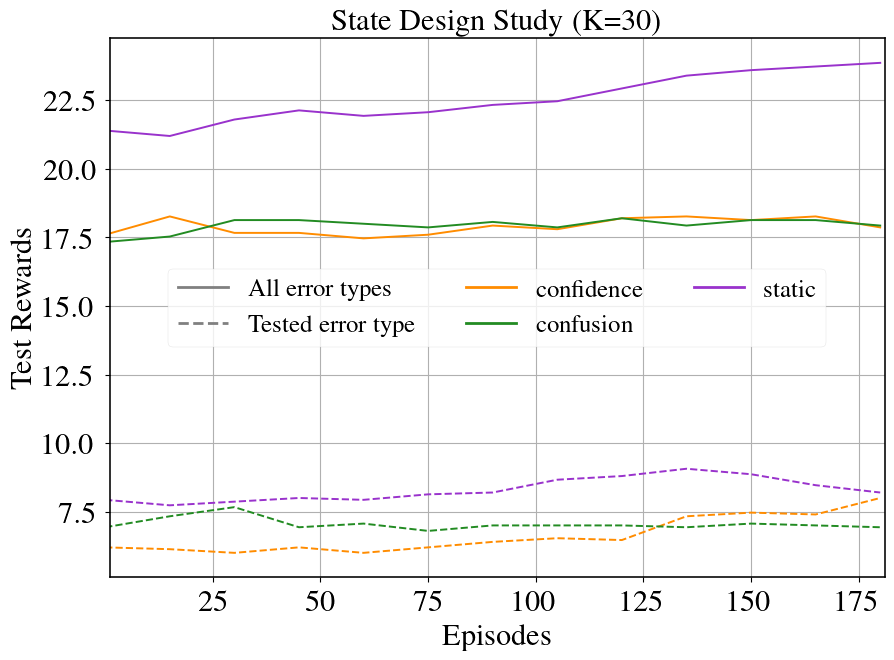

In [196]:
element = []
element_expl = []

lengths = []
N = 15
s = 70
file_base = '../vu2/RL4Auditing/tabular/state_study/'
list_result = ['noexpl_confidence_%dsteps.pkl'%s, 'noexpl_confusion_%dsteps.pkl'%s, 'noexpl_static_state_%dsteps.pkl'%s] #

for l in list_result:
    with open(file_base + l, 'rb') as file:
        data = pickle.load(file)
        values = average_chunks(data["test_reward"][:200], N)
        values_expl = average_chunks(data["test_reward_expl"][:200], N)
        element.append(values)
        lengths.append(len(values))
        element_expl.append(values_expl)
# window_size = 10
# averages = []
# averages_explain = []

# random_averages = []
# random_averages_explain = []

# # Ensure the list is large enough
# if len(random_selected_elements) >= window_size:
#     for i in range(window_size, len(random_selected_elements) + 1):
#         # Get the last 100 elements ending at index i
#         window = selected_elements[i - window_size:i]
#         average = sum(window) / window_size
#         averages.append(average)
        
#         window2 = selected_elements_expl[i - window_size:i]
#         average2 = sum(window2) / window_size
        
#         averages_explain.append(average2)

#         window = random_selected_elements[i - window_size:i]
#         average = sum(window) / window_size
#         random_averages.append(average)
        
#         window2 = random_selected_elements_expl[i - window_size:i]
#         average2 = sum(window2) / window_size
        
#         random_averages_explain.append(average2)
# # Create corresponding x-axis values (iterations)
# iterations = list(range(len(random_averages_explain)))

# Plot the selected elements
# colors = generate_colormap_colors(len(element), cmap='inferno')
colors = ['darkorange', 'forestgreen', 'darkorchid'] #, 'dodgerblue'
length = min(lengths)
plt.figure(figsize=(10, 7))
x_ticks = [i * N for i in range(length)]
for i in range(len(element)):
    print(element[i])
    plt.plot(x_ticks, element[i][:length], color=colors[i], linestyle='-')
    plt.plot(x_ticks, element_expl[i][:length], color=colors[i], linestyle='--')

# plt.plot(iterations, averages, marker='.', linestyle='-', color='b', label='Ours - All Errors')
# plt.plot(iterations, averages_explain, marker='.', linestyle='-', color='r', label='Ours - Expl Errors')
# plt.plot(iterations, random_averages, marker='.', linestyle='--', color='g', label='Random - All Errors')
# plt.plot(iterations, random_averages_explain, marker='.', linestyle='--', color='y', label='Random - Expl Errors')

# Create custom legend handles (only line styles)
legend_line_handles = [
    Line2D([0], [0], linestyle='-', color='gray', lw=2),  # Solid line
    Line2D([0], [0], linestyle='--', color='gray', lw=2),  # Dashed line
]

# Set the legend


# Create custom legend handles based on colors
legend_color_handles = []
for c in colors:
    legend_color_handles.append(Line2D([0], [0], color=c, lw=2))
    
combined_handles = legend_line_handles + legend_color_handles
combined_labels = ['All error types', 'Tested error type', 'confidence', 'confusion', 'static']

# Set the custom legend using the created handles
plt.legend(combined_handles, combined_labels, loc='center', ncol=3) #, loc='upper left', bbox_to_anchor=(1, 1)

plt.xlim(1, max(x_ticks) + 1)
# plt.tight_layout()

plt.xlabel('Episodes')
plt.ylabel('Test Rewards')
plt.title('State Design Study (K=30)')
plt.grid()
# plt.savefig(file_base+'generalizability_30.pdf', format='pdf', dpi=600)